# DnCNN 最佳模型：结构、单图及完整验证集评价

按顺序运行单元格。新会话无需先运行其他 Notebook。

### 1. 初始化、导入与设备

In [1]:
import math
from statistics import mean
import torch
from torch import nn
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
if (cwd / "src").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "src").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    raise RuntimeError("请从项目根目录或 notebooks/ 目录启动 Jupyter")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("项目目录：", PROJECT_ROOT)
from src.models.dncnn import DnCNN
from src.datasets.sidd_dataset import SIDDDataset
from src.inference import denoise_image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("设备：", device)


项目目录： D:\CodeRepository\graduation‑design
设备： cuda


### 2. 加载 best.pth 权重（不能误用 last）

In [2]:
weight_path = PROJECT_ROOT / "checkpoints" / "dncnn_sidd_best.pth"
assert weight_path.is_file(), f"找不到权重：{weight_path}"
model = DnCNN(in_channels=3, features=64, depth=20).to(device)
model.load_state_dict(torch.load(weight_path, map_location="cpu", weights_only=True))
model.eval()
print("已加载：", weight_path)


已加载： D:\CodeRepository\graduation‑design\checkpoints\dncnn_sidd_best.pth


### 3. 模型结构概览

In [3]:
conv = sum(isinstance(layer, nn.Conv2d) for layer in model.modules())
bn = sum(isinstance(layer, nn.BatchNorm2d) for layer in model.modules())
relu = sum(isinstance(layer, nn.ReLU) for layer in model.modules())
parameters = sum(p.numel() for p in model.parameters())
print(f"Conv2d：{conv}；BatchNorm2d：{bn}；ReLU：{relu}")
print(f"可训练参数：{parameters:,}")


Conv2d：20；BatchNorm2d：18；ReLU：19
可训练参数：670,531


### 4. 单张验证图像去噪

In [4]:
dataset = SIDDDataset(split="val")
sample_index = 0  # 可改为 0～45
noisy, gt = dataset[sample_index]
with torch.inference_mode():
    denoised = model(noisy.unsqueeze(0).to(device)).clamp(0, 1)[0].cpu()
print("样本索引：", sample_index, "图像尺寸：", tuple(noisy.shape))


样本索引： 0 图像尺寸： (3, 256, 256)


### 5. 单图三图对比与 PSNR

NOISY PSNR 36.20 → DnCNN PSNR 37.26 dB，提升 +1.06 dB


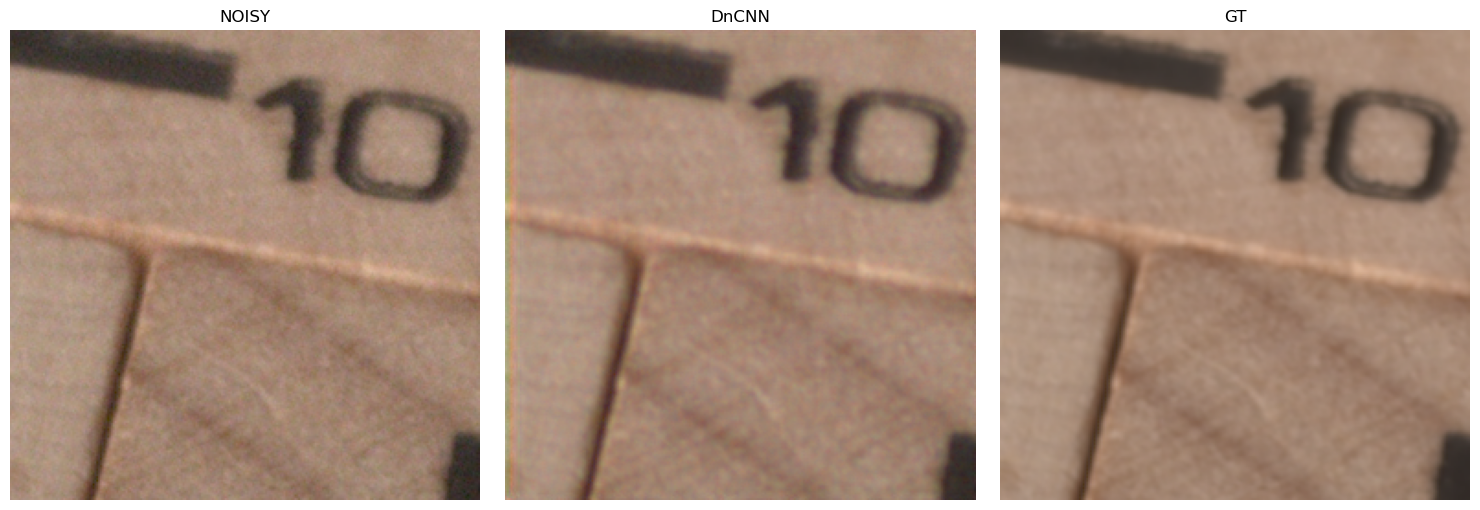

In [5]:
def psnr(a, b):
    mse = torch.mean((a - b) ** 2).item()
    return -10 * math.log10(max(mse, 1e-12))

noisy_psnr = psnr(noisy, gt)
denoised_psnr = psnr(denoised, gt)
print(f"NOISY PSNR {noisy_psnr:.2f} → DnCNN PSNR {denoised_psnr:.2f} dB，提升 {denoised_psnr-noisy_psnr:+.2f} dB")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, image, title in zip(axes, (noisy, denoised, gt), ("NOISY", "DnCNN", "GT")):
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


### 6. 全部 46 对验证集：PSNR、SSIM、Val Loss

In [6]:
# 保持和训练脚本一致：Val Loss 用未 clamp 输出；PSNR 使用 clamp 后输出。
# SSIM 使用 skimage 的 RGB channel_axis=2、data_range=1.0。
noisy_psnrs, denoised_psnrs = [], []
noisy_ssims, denoised_ssims, val_losses = [], [], []

def ssim(a, b):
    x = a.permute(1, 2, 0).numpy()
    y = b.permute(1, 2, 0).numpy()
    return structural_similarity(x, y, data_range=1.0, channel_axis=2)

model.eval()
with torch.inference_mode():
    for index in range(len(dataset)):
        n, clean = dataset[index]
        raw = model(n.unsqueeze(0).to(device))[0].cpu()
        val_losses.append(torch.mean((raw - clean)**2).item())
        pred = raw.clamp(0, 1)
        noisy_psnrs.append(psnr(n, clean))
        denoised_psnrs.append(psnr(pred, clean))
        noisy_ssims.append(ssim(n, clean))
        denoised_ssims.append(ssim(pred, clean))
print("验证图像数量：", len(dataset))
print(f"Val Loss：{mean(val_losses):.6f}")
print(f"PSNR：{mean(noisy_psnrs):.2f} → {mean(denoised_psnrs):.2f} dB（{mean(denoised_psnrs)-mean(noisy_psnrs):+.2f} dB）")
print(f"SSIM：{mean(noisy_ssims):.4f} → {mean(denoised_ssims):.4f}（{mean(denoised_ssims)-mean(noisy_ssims):+.4f}）")


验证图像数量： 46
Val Loss：0.000754
PSNR：29.33 → 32.90 dB（+3.57 dB）
SSIM：0.5811 → 0.7502（+0.1691）


### 7. 逐样本改善/下降数量和幅度

In [7]:
improvements = [after - before for before, after in zip(noisy_psnrs, denoised_psnrs)]
print("PSNR 改善的图像：", sum(d > 0 for d in improvements))
print("PSNR 下降的图像：", sum(d < 0 for d in improvements))
print("PSNR 不变的图像：", sum(d == 0 for d in improvements))
print(f"最大改善：{max(improvements):+.2f} dB")
print(f"最小改善（如为负值即下降）：{min(improvements):+.2f} dB")


PSNR 改善的图像： 44
PSNR 下降的图像： 2
PSNR 不变的图像： 0
最大改善：+5.63 dB
最小改善（如为负值即下降）：-0.50 dB


### 8. 改善最小的 5 张图及最差一张的视觉效果

索引 20: 38.83 → 38.32 dB (-0.50)
索引 21: 38.80 → 38.33 dB (-0.48)
索引 41: 37.37 → 37.55 dB (+0.18)
索引 40: 37.29 → 37.54 dB (+0.25)
索引 0: 36.20 → 37.26 dB (+1.06)


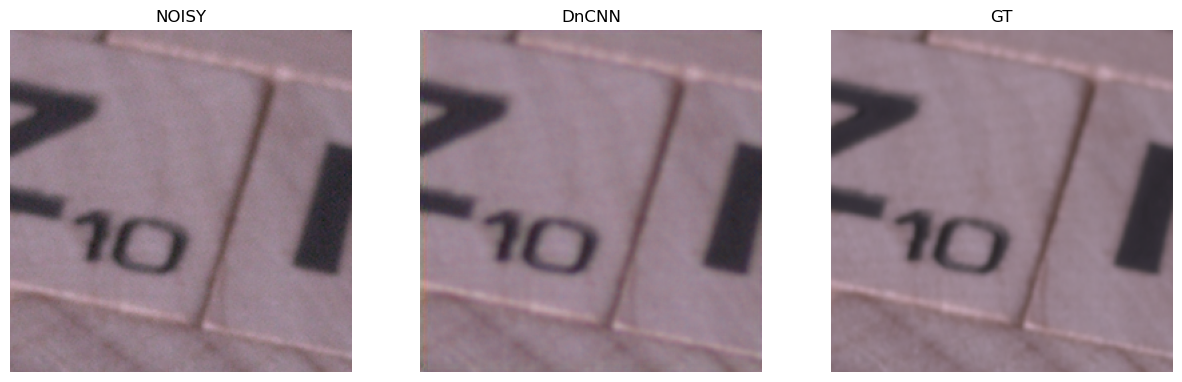

In [8]:
worst_indices = sorted(range(len(improvements)), key=lambda i: improvements[i])[:5]
for idx in worst_indices:
    print(f"索引 {idx}: {noisy_psnrs[idx]:.2f} → {denoised_psnrs[idx]:.2f} dB ({improvements[idx]:+.2f})")
idx = worst_indices[0]
n, clean = dataset[idx]
with torch.inference_mode():
    pred = model(n.unsqueeze(0).to(device)).clamp(0, 1)[0].cpu()
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, image, title in zip(axes, (n, pred, clean), ("NOISY", "DnCNN", "GT")):
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(title)
    ax.axis("off")
plt.show()


### 9. 可选：外部图片测试（不影响 46 对验证指标）

In [9]:
# 默认不运行外部图片去噪。若需要，填入本机路径（建议先用小图）。
EXTERNAL_IMAGE_PATH = None  # 示例：r"D:\Pictures\noisy.jpg"
if EXTERNAL_IMAGE_PATH is None:
    print("未指定外部图片，跳过")
else:
    from PIL import Image
    with Image.open(EXTERNAL_IMAGE_PATH) as photo:
        result = denoise_image(photo, model, tile_size=512)
    output_path = Path(EXTERNAL_IMAGE_PATH).with_name(Path(EXTERNAL_IMAGE_PATH).stem + "_dncnn.png")
    result.save(output_path, compress_level=1)
    print("已保存：", output_path)


未指定外部图片，跳过
